# Ejercicio 5: Reconstrucción en condiciones ideales

En este ejercicio reconstruimos el fantoma a partir de mediciones ideales, sin ruido, utilizando las matrices de proyección $A_2$, $A_4$ y $A_7$. Resolvemos cada sistema mediante mínimos cuadrados y analizamos cómo el rango y el espacio nulo de cada matriz afectan la posibilidad de recuperar correctamente la imagen original.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

## Código utilizado de ejercicios anteriores

In [6]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

x_fantoma = X_fantoma.reshape(-1)

def mascara_rayo(n, direccion, s):

    matriz = np.array([[0] * n for _ in range(n)])      # creamos una matriz de n x n de ceros

    for i in range(0, n):      
        for j in range(0, n):
            if direccion[0] * i + direccion[1] * j == s:        # comprobamos si el píxel (i, j) pertenece al rayo
                matriz[i, j] = 1        # si pertenece al rayo, marcamos esa posición con un 1

    return matriz       # devolvemos la máscara del rayo


def matriz_proyeccion(n, direcciones):

    matriz = []     # acá vamos a guardar los vectores de todas las máscaras
    rayo = []       # acá vamos a guardar los pares de s y (alfa, beta) de cada rayo

    for direccion in direcciones:

        valores_s = []      # acá guardamos todos los valores posibles de s para la dirección actual

        # recorremos todos los píxeles
        for i in range(n):
            for j in range(n):
                valores_s.append(direccion[0] * i + direccion[1] * j)       # calculamos el valor de s que le corresponde al píxel (i, j) para esta dirección

        valores_s = sorted(set(valores_s))      # eliminamos los valores repetidos de s y los ordenamos de menor a mayor

        for s in valores_s:

            rayo.append((tuple(direccion), s))

            mascara = mascara_rayo(n, direccion, s)     # generamos la máscara de este rayo particular
            matriz.append(mascara.reshape(-1))      # convertimos la máscara de n x n en un vector y lo agregamos como una nueva fila

    return np.array(matriz) , rayo

# D2
D2 = [(1, 0), (0, 1)]
A2, rayos_A2 = matriz_proyeccion(8, D2)
rango_A2 = np.linalg.matrix_rank(A2)
nul_A2 = 64 - rango_A2


# D4
D4 = D2 + [(1, 1), (1, -1)]
A4, rayos_A4 = matriz_proyeccion(8, D4)
rango_A4 = np.linalg.matrix_rank(A4)
nul_A4 = 64 - rango_A4

# D7
D7 = D4 + [(2, 1), (1, 2), (3, 1)]
A7, rayos_A7 = matriz_proyeccion(8, D7)
rango_A7 = np.linalg.matrix_rank(A7)
nul_A7 = 64 - rango_A7


## a) Reconstrucción mediante mínimos cuadrados

Para cada matriz de proyección generamos las mediciones ideales mediante $b_k=A_kx_{\text{fantoma}}$. Luego utilizamos `np.linalg.lstsq` para encontrar una reconstrucción $\widehat{x}_k$ que minimice $\|A_kx-b_k\|^2$.

En los casos de $A_2$ y $A_4$, el sistema no tiene una solución única y `lstsq` devuelve la solución de norma mínima. En el caso de $A_7$, como la matriz tiene rango columna completo, la solución es única.

In [7]:
# Para k = 2
b2 = A2 @ x_fantoma
x_raya_2 = np.linalg.lstsq(A2, b2, rcond=None)[0]

# Para k = 4
b4 = A4 @ x_fantoma
x_raya_4 = np.linalg.lstsq(A4, b4, rcond=None)[0]

# Para k =7
b7 = A7 @ x_fantoma
x_raya_7 = np.linalg.lstsq(A7, b7, rcond=None)[0]

## b) Residuo y error relativo

Para evaluar cada reconstrucción calculamos dos cantidades diferentes. El residuo $r_k=b_k-A_k\widehat{x}_k$ mide qué tan bien la reconstrucción reproduce las mediciones. El error relativo $\|\widehat{x}_k-x_{\text{fantoma}}\|/\|x_{\text{fantoma}}\|$ mide qué tan parecida es la imagen reconstruida a la imagen original.

In [8]:
# cols de la tabla
print(f"{'Matriz':<8} {'Rango':<8} {'Norma Residuo':<18} {'Error Relativo':<15}")
print("-"*52)

# Para k = 2
r2 = b2 - A2 @ x_raya_2
norm_r2 = np.linalg.norm(r2)
err_2 = np.linalg.norm(x_raya_2 - x_fantoma)/np.linalg.norm(x_fantoma)
print(f"{'A2':<8} {rango_A2:<8} {norm_r2:<18.2e} {err_2:<15.4f}")

# Para k = 4
r4 = b4 - A4 @ x_raya_4
norm_r4 = np.linalg.norm(r4)
err_4 = np.linalg.norm(x_raya_4 - x_fantoma)/np.linalg.norm(x_fantoma)
print(f"{'A4':<8} {rango_A4:<8} {norm_r4:<18.2e} {err_4:<15.4f}")

# Para k = 7
r7 = b7 - A7 @ x_raya_7
norm_r7 = np.linalg.norm(r7)
err_7= np.linalg.norm(x_raya_7 - x_fantoma)/np.linalg.norm(x_fantoma)
print(f"{'A7':<8} {rango_A7:<8} {norm_r7:<18.2e} {err_7:<15.4f}")

Matriz   Rango    Norma Residuo      Error Relativo 
----------------------------------------------------
A2       15       2.56e-15           0.4689         
A4       39       1.59e-14           0.1365         
A7       64       1.10e-14           0.0000         


Los residuos obtenidos son del orden de $10^{-14}$, por lo que numéricamente pueden considerarse iguales a cero. Esto indica que las tres reconstrucciones reproducen correctamente las mediciones ideales. Sin embargo, los errores relativos son diferentes. Para $A_2$ y $A_4$ son distintos de cero, mientras que para $A_7$ el error es aproximadamente nulo. Por lo tanto, reproducir correctamente las mediciones no siempre implica haber recuperado correctamente la imagen original.

## c) Comparación visual de las reconstrucciones

Visualizamos el fantoma original, la imagen reconstruida y la diferencia absoluta entre ambas para cada matriz de proyección. Utilizamos una escala de colores común para las imágenes y otra escala común para las diferencias, de manera que los resultados puedan compararse correctamente.


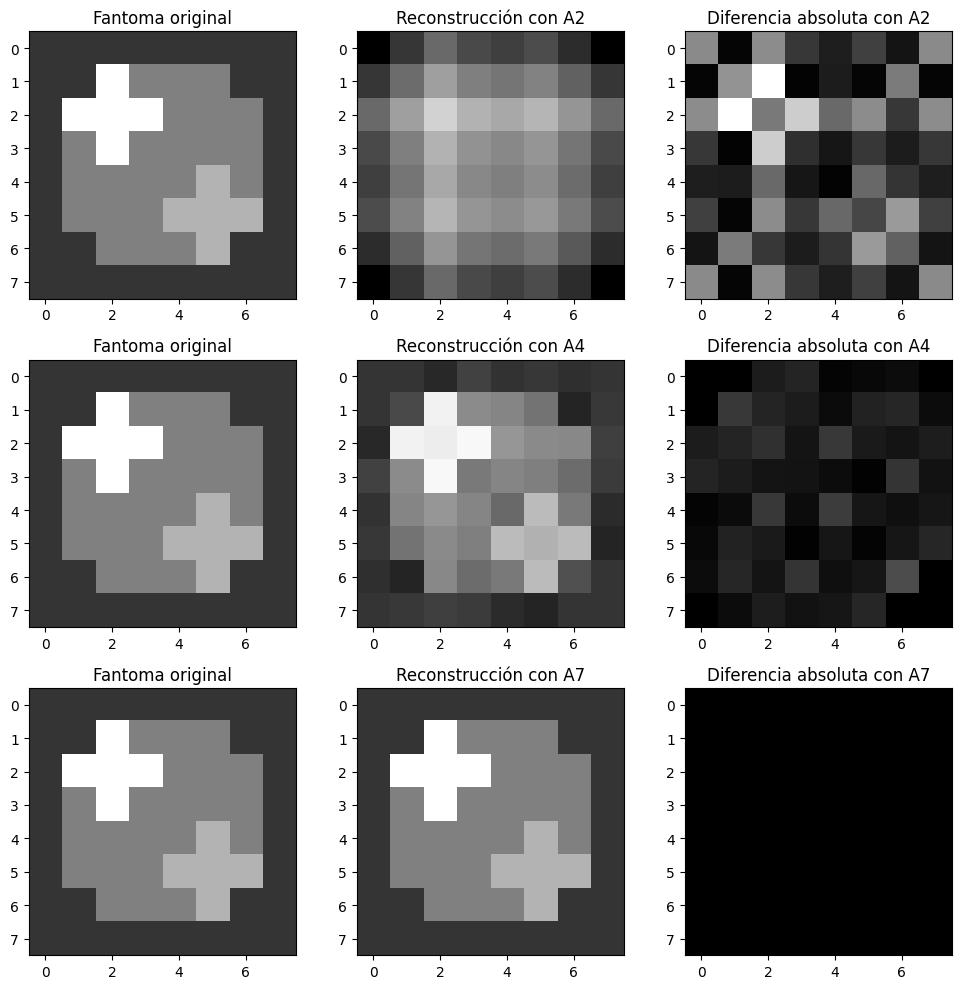

In [9]:
# Recuperamos las representaciones matriciales de las reconstrucciones
X_2_rec = x_raya_2.reshape(8, 8)
X_4_rec = x_raya_4.reshape(8, 8)
X_7_rec = x_raya_7.reshape(8, 8)

# Calculamos las diferencias absolutas con respecto al fantoma original
dif_2 = np.abs(X_2_rec - X_fantoma)
dif_4 = np.abs(X_4_rec - X_fantoma)
dif_7 = np.abs(X_7_rec - X_fantoma)

# Calculamos una escala común para comparar el fantoma y las reconstrucciones
vmin_imagenes = min(X_fantoma.min(), X_2_rec.min(), X_4_rec.min(), X_7_rec.min())
vmax_imagenes = max(X_fantoma.max(), X_2_rec.max(), X_4_rec.max(), X_7_rec.max())

# Calculamos una escala común para comparar las tres diferencias
vmax_diferencias = max(dif_2.max(), dif_4.max(), dif_7.max())

# Creamos una grilla de 3 filas y 3 columnas
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

# Reconstrucción con A2
axes[0, 0].imshow(X_fantoma, cmap="gray", vmin=vmin_imagenes, vmax=vmax_imagenes)
axes[0, 0].set_title("Fantoma original")

axes[0, 1].imshow(X_2_rec, cmap="gray", vmin=vmin_imagenes, vmax=vmax_imagenes)
axes[0, 1].set_title("Reconstrucción con A2")

im = axes[0, 2].imshow(dif_2, cmap="gray", vmin=0, vmax=vmax_diferencias)
axes[0, 2].set_title("Diferencia absoluta con A2")

# Reconstrucción con A4
axes[1, 0].imshow(X_fantoma, cmap="gray", vmin=vmin_imagenes, vmax=vmax_imagenes)
axes[1, 0].set_title("Fantoma original")

axes[1, 1].imshow(X_4_rec, cmap="gray", vmin=vmin_imagenes, vmax=vmax_imagenes)
axes[1, 1].set_title("Reconstrucción con A4")

im = axes[1, 2].imshow(dif_4, cmap="gray", vmin=0, vmax=vmax_diferencias)
axes[1, 2].set_title("Diferencia absoluta con A4")

# Reconstrucción con A7
axes[2, 0].imshow(X_fantoma, cmap="gray", vmin=vmin_imagenes, vmax=vmax_imagenes)
axes[2, 0].set_title("Fantoma original")

axes[2, 1].imshow(X_7_rec, cmap="gray", vmin=vmin_imagenes, vmax=vmax_imagenes)
axes[2, 1].set_title("Reconstrucción con A7")

im = axes[2, 2].imshow(dif_7, cmap="gray", vmin=0, vmax=vmax_diferencias)
axes[2, 2].set_title("Diferencia absoluta con A7")

plt.tight_layout()
plt.show()

Un residuo cercano a cero indica que la imagen reconstruida reproduce correctamente las mediciones, ya que $A_k\widehat{x}_k\approx b_k$. Sin embargo, esto no garantiza que $\widehat{x}_k$ coincida con el fantoma original.

Para $A_2$ y $A_4$, el espacio nulo tiene dimensión mayor que cero. Como el fantoma y la reconstrucción producen aproximadamente las mismas mediciones, se cumple que $A_k(x_{\text{fantoma}}-\widehat{x}_k)\approx0$. Por lo tanto, la diferencia entre ambas imágenes pertenece aproximadamente al espacio nulo de $A_k$ y resulta invisible para los rayos utilizados.

En estos casos existen varias imágenes capaces de producir las mismas mediciones. `np.linalg.lstsq` elige entre ellas la solución de norma mínima, que no necesariamente coincide con el fantoma original. Por eso obtenemos residuos prácticamente nulos, pero errores relativos distintos de cero.

Al incorporar más direcciones, aumentamos el rango de la matriz y reducimos la dimensión de su espacio nulo. Por este motivo, la reconstrucción obtenida con $A_4$ se aproxima más al fantoma que la obtenida con $A_2$.

En cambio, $A_7$ tiene rango 64 y su espacio nulo contiene únicamente al vector cero. En este caso, la solución es única y la reconstrucción coincide numéricamente con el fantoma original, con un error relativo aproximadamente igual a cero.